In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

classes = ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
device = "cuda"

tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model.load_state_dict(torch.load("/content/drive/MyDrive/WBC-Folder/resnet18_wbc_v2.pt", map_location=device))
model = model.to(device).eval()
print("model ready")

Mounted at /content/drive
model ready


In [2]:
import pandas as pd

use = pd.read_csv("/content/drive/MyDrive/WBC-Folder/mll23_predictions_v2.csv")
core = use[use["label"] != "neutrophil_band"].copy()
core["right"] = core["pred"] == core["label"]

print("accuracy on the 7 matching classes:", round(core["right"].mean(), 3))
hi = core["conf"] >= 0.90
print("share of predictions made at 90%+ confidence:", round(hi.mean(), 3))
print("accuracy among 90%+ predictions:", round(core[hi]["right"].mean(), 3))
print("accuracy among predictions below 90%:", round(core[~hi]["right"].mean(), 3))

bins = [0, 0.5, 0.7, 0.9, 0.99, 1.0001]
core["conf_bin"] = pd.cut(core["conf"], bins)
print()
print(core.groupby("conf_bin", observed=True)["right"].agg(["count", "mean"]).round(3))
print()
print(core.groupby("pred")["conf"].agg(["count", "mean"]).round(3))

accuracy on the 7 matching classes: 0.272
share of predictions made at 90%+ confidence: 0.499
accuracy among 90%+ predictions: 0.396
accuracy among predictions below 90%: 0.148

             count   mean
conf_bin                 
(0.0, 0.5]    1487  0.128
(0.5, 0.7]    4032  0.143
(0.7, 0.9]    5662  0.156
(0.9, 0.99]   7047  0.241
(0.99, 1.0]   4094  0.662

              count   mean
pred                      
basophil        726  0.725
eosinophil       69  0.558
erythroblast   4629  0.831
ig             2090  0.763
lymphocyte      307  0.650
monocyte      14458  0.848
neutrophil       35  0.567
platelet          8  0.598


In [2]:
%%bash
mkdir -p /content/zips /content/mll
cd /content/zips
for n in basophil eosinophil lymphocyte monocyte neutrophil_band neutrophil_segmented normoblast metamyelocyte myelocyte promyelocyte; do
  if [ -d /content/mll/$n ] && [ "$(ls -A /content/mll/$n)" ]; then echo "skip $n"; continue; fi
  wget -nv -c -O $n.zip "https://zenodo.org/records/14277609/files/$n.zip?download=1" || { echo "FAILED $n"; continue; }
  mkdir -p /content/mll/$n
  unzip -oq $n.zip -d /content/mll/$n
  rm $n.zip
  echo "done $n"
done

done basophil
done eosinophil
done lymphocyte
done monocyte
done neutrophil_band
done neutrophil_segmented
done normoblast
done metamyelocyte
done myelocyte
done promyelocyte


2026-11-03 11:21:11 URL:https://zenodo.org/records/14277609/files/basophil.zip?download=1 [146551118/146551118] -> "basophil.zip" [1]
2026-11-03 11:25:35 URL:https://zenodo.org/records/14277609/files/eosinophil.zip?download=1 [559740026/559740026] -> "eosinophil.zip" [1]
2026-11-03 11:33:49 URL:https://zenodo.org/records/14277609/files/lymphocyte.zip?download=1 [1312605314/1312605314] -> "lymphocyte.zip" [1]
2026-11-03 11:38:18 URL:https://zenodo.org/records/14277609/files/monocyte.zip?download=1 [615145392/615145392] -> "monocyte.zip" [1]
2026-11-03 11:41:07 URL:https://zenodo.org/records/14277609/files/neutrophil_band.zip?download=1 [158662394/158662394] -> "neutrophil_band.zip" [1]
2026-11-03 11:51:56 URL:https://zenodo.org/records/14277609/files/neutrophil_segmented.zip?download=1 [1752594464/1752594464] -> "neutrophil_segmented.zip" [1]
2026-11-03 11:55:03 URL:https://zenodo.org/records/14277609/files/normoblast.zip?download=1 [374948659/374948659] -> "normoblast.zip" [1]
2026-11-

In [3]:
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

norm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def shrink_pad(img, s, size=224):
    inner = int(size * s)
    small = img.resize((inner, inner))
    arr = np.array(img)
    border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
    bg = tuple(int(v) for v in np.median(border, axis=0))
    canvas = Image.new("RGB", (size, size), bg)
    off = (size - inner) // 2
    canvas.paste(small, (off, off))
    return canvas

class ScaleSet(Dataset):
    def __init__(self, paths, s):
        self.paths, self.s = paths, s
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return norm(shrink_pad(img, self.s))

core = pd.read_csv("/content/drive/MyDrive/WBC-Folder/mll23_predictions_v2.csv")
core = core[core["label"] != "neutrophil_band"]
sample = pd.concat([d.sample(300, random_state=0) for _, d in core.groupby("label")]).reset_index(drop=True)

for s in [1.0, 0.8, 0.65, 0.5]:
    loader = DataLoader(ScaleSet(sample["path"].tolist(), s), batch_size=128, num_workers=2)
    preds = []
    with torch.no_grad():
        for x in loader:
            preds += [classes[k] for k in model(x.to(device)).argmax(1).cpu().tolist()]
    preds = np.array(preds)
    print(f"scale {s:.2f}: accuracy {(preds == sample['label'].values).mean():.3f} | share called monocyte {(preds == 'monocyte').mean():.3f}")

scale 1.00: accuracy 0.450 | share called monocyte 0.528
scale 0.80: accuracy 0.510 | share called monocyte 0.510
scale 0.65: accuracy 0.565 | share called monocyte 0.350
scale 0.50: accuracy 0.469 | share called monocyte 0.197


Saving BNE_56697.jpg to BNE_56697.jpg
reference: BNE_56697.jpg (363, 360, 3)


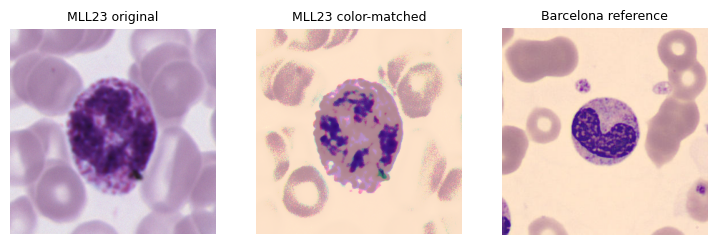

color matched, scale 1.00: accuracy 0.171 | share called monocyte 0.016
color matched, scale 0.65: accuracy 0.192 | share called monocyte 0.001


In [4]:
from google.colab import files
from skimage.exposure import match_histograms
import matplotlib.pyplot as plt

up = files.upload()
ref_name = list(up.keys())[0]
ref = np.array(Image.open(ref_name).convert("RGB"))
print("reference:", ref_name, ref.shape)

# look at one cell before and after color matching
orig = np.array(Image.open(sample["path"].iloc[0]).convert("RGB"))
matched = np.clip(match_histograms(orig, ref, channel_axis=-1), 0, 255).astype("uint8")
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, im, t in zip(ax, [orig, matched, ref], ["MLL23 original", "MLL23 color-matched", "Barcelona reference"]):
    a.imshow(im); a.set_title(t, fontsize=9); a.axis("off")
plt.show()

class ColorSet(Dataset):
    def __init__(self, paths, s, ref):
        self.paths, self.s, self.ref = paths, s, ref
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        arr = match_histograms(np.array(img), self.ref, channel_axis=-1)
        img = Image.fromarray(np.clip(arr, 0, 255).astype("uint8"))
        return norm(shrink_pad(img, self.s))

for s in [1.0, 0.65]:
    loader = DataLoader(ColorSet(sample["path"].tolist(), s, ref), batch_size=128, num_workers=2)
    preds = []
    with torch.no_grad():
        for x in loader:
            preds += [classes[k] for k in model(x.to(device)).argmax(1).cpu().tolist()]
    preds = np.array(preds)
    print(f"color matched, scale {s:.2f}: accuracy {(preds == sample['label'].values).mean():.3f} | share called monocyte {(preds == 'monocyte').mean():.3f}")

Barcelona background RGB: [255. 228. 203.]


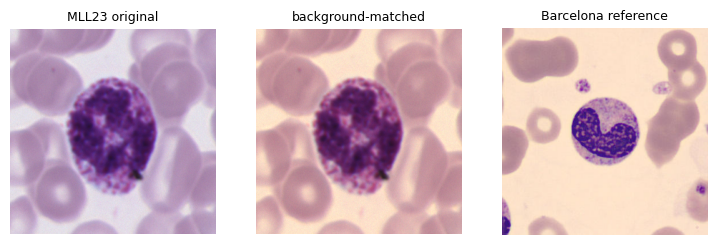

background matched, scale 1.00: accuracy 0.492 | share called monocyte 0.204
background matched, scale 0.65: accuracy 0.634 | share called monocyte 0.152


In [5]:
def bg_color(arr):
    flat = arr.reshape(-1, 3).astype("float32")
    lum = flat.mean(axis=1)
    return np.median(flat[lum >= np.percentile(lum, 90)], axis=0)

ref_bg = bg_color(np.array(ref))
print("Barcelona background RGB:", ref_bg)

def bg_match(img, ref_bg):
    arr = np.array(img).astype("float32")
    gain = ref_bg / np.maximum(bg_color(arr), 1)
    return Image.fromarray(np.clip(arr * gain, 0, 255).astype("uint8"))

class BgSet(Dataset):
    def __init__(self, paths, s, ref_bg):
        self.paths, self.s, self.ref_bg = paths, s, ref_bg
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return norm(shrink_pad(bg_match(img, self.ref_bg), self.s))

orig = Image.open(sample["path"].iloc[0]).convert("RGB")
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, im, t in zip(ax, [orig, bg_match(orig, ref_bg), Image.fromarray(np.array(ref))], ["MLL23 original", "background-matched", "Barcelona reference"]):
    a.imshow(im); a.set_title(t, fontsize=9); a.axis("off")
plt.show()

for s in [1.0, 0.65]:
    loader = DataLoader(BgSet(sample["path"].tolist(), s, ref_bg), batch_size=128, num_workers=2)
    preds = []
    with torch.no_grad():
        for x in loader:
            preds += [classes[k] for k in model(x.to(device)).argmax(1).cpu().tolist()]
    preds = np.array(preds)
    print(f"background matched, scale {s:.2f}: accuracy {(preds == sample['label'].values).mean():.3f} | share called monocyte {(preds == 'monocyte').mean():.3f}")

In [ ]:
from pathlib import Path

exts = {".tif", ".tiff", ".jpg", ".jpeg", ".png"}
rows = []
for folder in sorted(Path("/content/mll").iterdir()):
    files = [p for p in folder.rglob("*")
             if p.suffix.lower() in exts and not p.name.startswith(".") and "__MACOSX" not in p.parts]
    im = Image.open(files[0])
    print(f"{folder.name:22s} {len(files):6d} images | example size {im.size}, type {files[0].suffix}")
    rows.extend({"path": str(p), "folder": folder.name} for p in files)
mll = pd.DataFrame(rows)

mapping = {
    "neutrophil_segmented": "neutrophil",
    "neutrophil_band": "neutrophil_band",
    "eosinophil": "eosinophil",
    "basophil": "basophil",
    "lymphocyte": "lymphocyte",
    "monocyte": "monocyte",
    "metamyelocyte": "ig",
    "myelocyte": "ig",
    "promyelocyte": "ig",
    "normoblast": "erythroblast",
}
mll["label"] = mll["folder"].map(mapping)
print(mll["label"].value_counts())

basophil                  616 images | example size (288, 288), type .TIF
eosinophil               2448 images | example size (288, 288), type .TIF
lymphocyte               5532 images | example size (288, 288), type .TIF
metamyelocyte             483 images | example size (288, 288), type .TIF
monocyte                 2510 images | example size (288, 288), type .TIF
myelocyte                 747 images | example size (288, 288), type .TIF
neutrophil_band           687 images | example size (288, 288), type .TIF
neutrophil_segmented     7170 images | example size (288, 288), type .TIF
normoblast               2071 images | example size (288, 288), type .TIF
promyelocyte              745 images | example size (288, 288), type .TIF
label
neutrophil         7170
lymphocyte         5532
monocyte           2510
eosinophil         2448
erythroblast       2071
ig                 1975
neutrophil_band     687
basophil            616
Name: count, dtype: int64


In [ ]:
class MLLSet(Dataset):
    def __init__(self, paths):
        self.paths = paths
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return tfm(Image.open(self.paths[i]).convert("RGB"))

use = mll[mll["label"].notna()].reset_index(drop=True)
loader = DataLoader(MLLSet(use["path"].tolist()), batch_size=128, shuffle=False, num_workers=2)

preds, confs = [], []
with torch.no_grad():
    for x in loader:
        p = F.softmax(model(x.to(device)), dim=1)
        c, i = p.max(1)
        preds += [classes[k] for k in i.cpu().tolist()]
        confs += c.cpu().tolist()

use["pred"] = preds
use["conf"] = confs
use.to_csv("/content/drive/MyDrive/WBC-Folder/mll23_predictions_v2.csv", index=False)
print("images scored:", len(use))
pd.crosstab(use["label"], use["pred"])

images scored: 23009


pred,basophil,eosinophil,erythroblast,ig,lymphocyte,monocyte,neutrophil,platelet
label,,,,,,,,
basophil,353,2,10,39,0,212,0,0
eosinophil,40,64,56,668,0,1619,1,0
erythroblast,2,0,1972,4,75,18,0,0
ig,0,0,64,1063,0,848,0,0
lymphocyte,3,0,1652,5,231,3640,0,1
monocyte,0,0,162,2,0,2345,0,1
neutrophil,328,3,713,309,1,5776,34,6
neutrophil_band,8,1,53,174,0,451,0,0


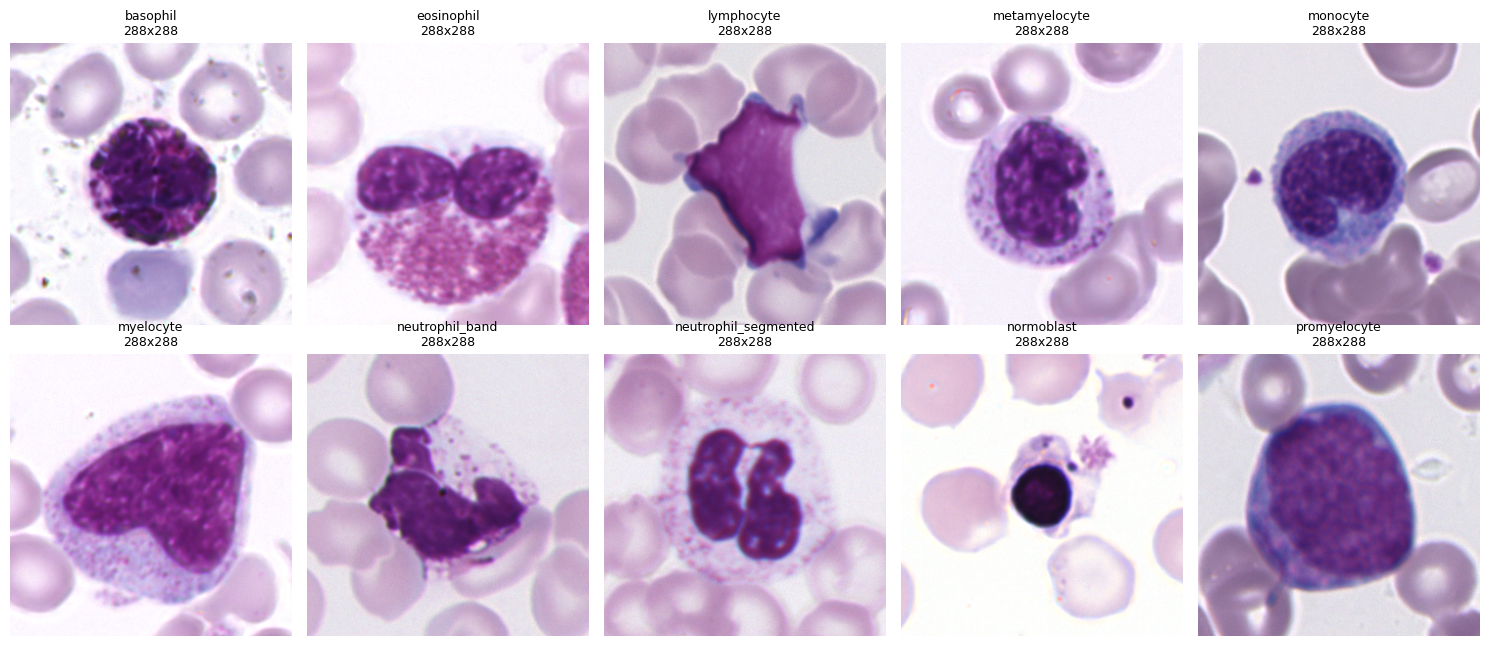

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax, folder in zip(axes.flat, sorted(mll["folder"].unique())):
    p = mll[mll["folder"] == folder].sample(1, random_state=1).iloc[0]["path"]
    im = Image.open(p).convert("RGB")
    ax.imshow(im)
    ax.set_title(f"{folder}\n{im.size[0]}x{im.size[1]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()